# 0. Описание задачи

## Задача многоклассовой классификации: на основе признаков разной природы предсказать результат шахматной партии.

* **Название датасета:** Chess Game Dataset (Lichess) — набор из 16 признаков (один из них целевой — результат партии `winner`), описывающих шахматную партию на платформе Lichess.org.
* **Размер датасета:** 20 058 партий.
* **Количество классов:** 3 (`white` — победа белых, `black` — победа черных, `draw` — ничья).


## 1. Чтение данных и первичный осмотр

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import kagglehub

In [58]:
path = kagglehub.dataset_download("datasnaek/chess")
data_raw = pd.read_csv(f"{path}/games.csv")

Using Colab cache for faster access to the 'chess' dataset.


In [59]:
data_raw.shape

(20058, 16)

In [60]:
data_raw.head()

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5


Расшифруем, что значит каждый конкретный столбец (признак):

1. `id` — идентификатор партии в системе
2. `rated` — рейтинговая или товарищеская игра (`True` / `False`)
3. `created_at` — время начала партии (Unix timestamp в мс)
4. `last_move_at` — время окончания партии (Unix timestamp в мс)
5. `turns` — количество полуходов в партии
6. `victory_status` — причина окончания партии (`mate` — мат, `resign` — сдача, `outoftime` — вышло время, `draw` — ничья)
7. `winner` — победитель (`white` — белые, `black` — черные, `draw` — ничья) — **целевой признак**
8. `increment_code` — контроль времени (изначальное время в минутах + добавление в секундах за каждый ход)
9. `white_id` — никнейм игрока за белых
10. `white_rating` — рейтинг белых
11. `black_id` — никнейм игрока за черных
12. `black_rating` — рейтинг черных
13. `moves` — все ходы партии в стандартной нотации
14. `opening_eco` — стандартизированный код дебюта (например, код испанской партии — `C60`)
15. `opening_name` — название дебюта
16. `opening_ply` — количество полуходов, которые полностью определяют дебют

In [61]:
data_raw.created_at[0], data_raw.last_move_at[0]

(np.float64(1504210000000.0), np.float64(1504210000000.0))

In [62]:
(data_raw['created_at'] == data_raw['last_move_at']).sum()

np.int64(8548)

In [63]:
diff_ms = data_raw['last_move_at'] - data_raw['created_at']

max_index = diff_ms.idxmax()
data_raw.loc[[max_index]]

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
10754,eyhzu8aj,False,1.389883e+12,1.390489e+12,35,resign,white,180+180,towhen,1245,miladghasemi,1011,d4 f6 Nf3 e5 e3 Nc6 Nc3 d5 Nb5 Qd7 Bd2 a6 Na3 ...,A40,Queen's Pawn,1


Покажем, что количество ходов `turns` — на самом деле количество полуходов:

In [64]:
data_raw.moves[0], len(data_raw.moves[0].split()), data_raw.turns[0]

('d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5 Bf4', 13, np.int64(13))

In [65]:
data_raw['victory_status'].value_counts()

,count
victory_status,
resign,11147
mate,6325
outoftime,1680
draw,906


In [66]:
data_raw['winner'].value_counts()

,count
winner,
white,10001
black,9107
draw,950


### Анализ аномалии со временем (`created_at` и `last_move_at`), утечек данных и извлечение признаков из ходов (`moves`)

1. **Почему совпадают `created_at` и `last_move_at`:** В 8 548 партиях из 20 058 (`42.6%` датасета) время начала и окончания в точности совпадают (`1.504210e+12`). Это артефакт округления при экспорте датасета автором: в первой части таблицы таймстемпы в миллисекундах были сохранены в экспоненциальной записи с 6 значащими цифрами (шаг последнего разряда $10^7$ мс $\approx 2.77$ часа), из-за чего длительность обычных партий обнулилась. Кроме того, сами абсолютные отметки времени (год/месяц проведения партии) не влияют на исход борьбы на доске и коррелируют друг с другом с коэффициентом `1.0`.
2. **Удаление идентификаторов и утечек (`Data Leakage`):** Признаки `id`, `white_id`, `black_id` являются техническими идентификаторами, а признак `victory_status` напрямую раскрывает ничью (`victory_status == 'draw'` однозначно определяет `winner == 'draw'`). Их необходимо исключить.
3. **Feature Engineering по нотации ходов (`moves`):**
   В строке `moves` полуходы на четных индексах (`0, 2, 4, ...`) делают **белые**, а на нечетных (`1, 3, 5, ...`) — **черные**. Извлечем из партии содержательные шахматные признаки (намеренно не используя символ мата `#`, чтобы не создавать тривиальную утечку):
   * Взятия фигур (`x`): `white_captures`, `black_captures` и материальный баланс `captures_diff = white_captures - black_captures`.
   * Шахи королю (`+`): `white_checks`, `black_checks` и разница шахов `checks_diff` (показатель атакующей инициативы).
   * Рокировка (`O-O` / `O-O-O`): `white_castled`, `black_castled` (безопасность короля).
   * Превращения пешек (`=`): `white_promotions`, `black_promotions`, `promotions_diff`.
   * Активность ферзя (`Q...`): `white_queen_moves`, `black_queen_moves`.
   * Также вычислим разницу рейтингов `rating_diff = white_rating - black_rating`, распарсим `increment_code` на базовое время (`base_time`) и добавление (`increment`), и сгруппируем `opening_eco` по томам (`A`, `B`, `C`, `D`, `E`).

In [67]:
def build_chess_features(df):
    data = df.copy()

    # 1. Разница рейтингов
    data['rating_diff'] = data['white_rating'] - data['black_rating']

    # 2. Парсинг контроля времени increment_code (например, "15+2" -> 15 и 2)
    time_split = data['increment_code'].str.split('+', expand=True)
    data['base_time'] = pd.to_numeric(time_split[0], errors='coerce')
    data['increment'] = pd.to_numeric(time_split[1], errors='coerce')

    # 3. Группировка кода дебюта по томам ЭШД (A, B, C, D, E)
    data['eco_group'] = data['opening_eco'].str[0]

    # 4. Извлечение шахматных признаков из строки ходов moves
    w_cap, b_cap = [], []
    w_chk, b_chk = [], []
    w_cas, b_cas = [], []
    w_prom, b_prom = [], []
    w_queen, b_queen = [], []

    for moves_str in data['moves']:
        moves = str(moves_str).split()
        w_moves = moves[0::2]  # Полуходы белых (четные индексы)
        b_moves = moves[1::2]  # Полуходы черных (нечетные индексы)

        w_cap.append(sum('x' in m for m in w_moves))
        b_cap.append(sum('x' in m for m in b_moves))

        w_chk.append(sum('+' in m for m in w_moves))
        b_chk.append(sum('+' in m for m in b_moves))

        w_cas.append(int(any('O-O' in m for m in w_moves)))
        b_cas.append(int(any('O-O' in m for m in b_moves)))

        w_prom.append(sum('=' in m for m in w_moves))
        b_prom.append(sum('=' in m for m in b_moves))

        w_queen.append(sum(m.startswith('Q') for m in w_moves))
        b_queen.append(sum(m.startswith('Q') for m in b_moves))

    data['white_captures'] = w_cap
    data['black_captures'] = b_cap
    data['captures_diff'] = data['white_captures'] - data['black_captures']

    data['white_checks'] = w_chk
    data['black_checks'] = b_chk
    data['checks_diff'] = data['white_checks'] - data['black_checks']

    data['white_castled'] = w_cas
    data['black_castled'] = b_cas

    data['white_promotions'] = w_prom
    data['black_promotions'] = b_prom
    data['promotions_diff'] = data['white_promotions'] - data['black_promotions']

    data['white_queen_moves'] = w_queen
    data['black_queen_moves'] = b_queen

    # Удаляем неинформативные ID, сырые тексты, испорченные таймстемпы и утечку (victory_status)
    cols_to_drop = [
        'id', 'white_id', 'black_id',
        'created_at', 'last_move_at',
        'moves', 'opening_name', 'opening_eco', 'increment_code',
        'victory_status'
    ]
    data = data.drop(columns=cols_to_drop)
    return data

data = build_chess_features(data_raw)
print("Новая размерность датасета:", data.shape)
data.head()

Новая размерность датасета: (20058, 23)


,rated,turns,winner,white_rating,black_rating,opening_ply,rating_diff,base_time,increment,eco_group,...,white_checks,black_checks,checks_diff,white_castled,black_castled,white_promotions,black_promotions,promotions_diff,white_queen_moves,black_queen_moves
0,False,13,white,1500,1191,5,309,15,2,D,...,0,1,-1,0,0,0,0,0,0,0
1,True,16,black,1322,1261,4,61,5,10,B,...,1,1,0,0,0,0,0,0,2,0
2,True,61,white,1496,1500,3,-4,5,10,C,...,8,0,8,0,0,0,0,0,3,1
3,True,61,white,1439,1454,3,-15,20,0,D,...,12,0,12,1,1,0,0,0,10,2
4,True,95,white,1523,1469,5,54,30,3,C,...,4,4,0,1,1,1,0,1,4,5


## 2. Разбиение данных на обучающую и тестовую выборки

Разобьем данные на обучающую (`75%`) и тестовую (`25%`) выборки.

Поскольку в данных присутствует сильный дисбаланс класса `draw` (`~4.7%`), используем стратификацию (`stratify=data['winner']`), чтобы сохранить одинаковые пропорции классов в обеих выборках.

In [68]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    data, test_size=0.25, random_state=42, stratify=data['winner']
)

print(f"Обучающая выборка (train_df): {train_df.shape[0]} объектов")
print(f"Тестовая выборка  (test_df):  {test_df.shape[0]} объектов")
print("\nРаспределение классов в обучающей выборке (в долях):")
print(train_df['winner'].value_counts(normalize=True))

Обучающая выборка (train_df): 15043 объектов
Тестовая выборка  (test_df):  5015 объектов

Распределение классов в обучающей выборке (в долях):
winner
white    0.498637
black    0.454032
draw     0.047331
Name: proportion, dtype: float64


## 3. Визуализация данных и вычисление основных характеристик

Вычислим основные статистические характеристики (среднее, разброс, квартили, минимум и максимум) и построим графики распределений и матрицу корреляций по обучающей выборке.

In [69]:
# Основные статистические характеристики числовых признаков
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
turns,15043.0,60.479825,33.579262,1.0,37.0,55.0,79.0,349.0
white_rating,15043.0,1595.145317,290.424969,784.0,1398.0,1566.0,1791.0,2700.0
black_rating,15043.0,1588.072525,290.350026,789.0,1389.0,1561.0,1782.0,2723.0
opening_ply,15043.0,4.804893,2.801342,1.0,3.0,4.0,6.0,28.0
rating_diff,15043.0,7.072791,248.590015,-1605.0,-108.0,4.0,123.0,1499.0
base_time,15043.0,13.931796,17.610377,0.0,10.0,10.0,15.0,180.0
increment,15043.0,5.283521,14.511616,0.0,0.0,0.0,8.0,180.0
white_captures,15043.0,7.201489,3.856196,0.0,4.0,7.0,10.0,15.0
black_captures,15043.0,7.146181,3.867362,0.0,4.0,7.0,10.0,15.0
captures_diff,15043.0,0.055308,2.456617,-12.0,-1.0,0.0,1.0,12.0


In [70]:
# Характеристики категориальных и булевых признаков
train_df.describe(include=['object', 'bool']).T

,count,unique,top,freq
rated,15043,2,True,12112
winner,15043,3,white,7501
eco_group,15043,5,C,5746


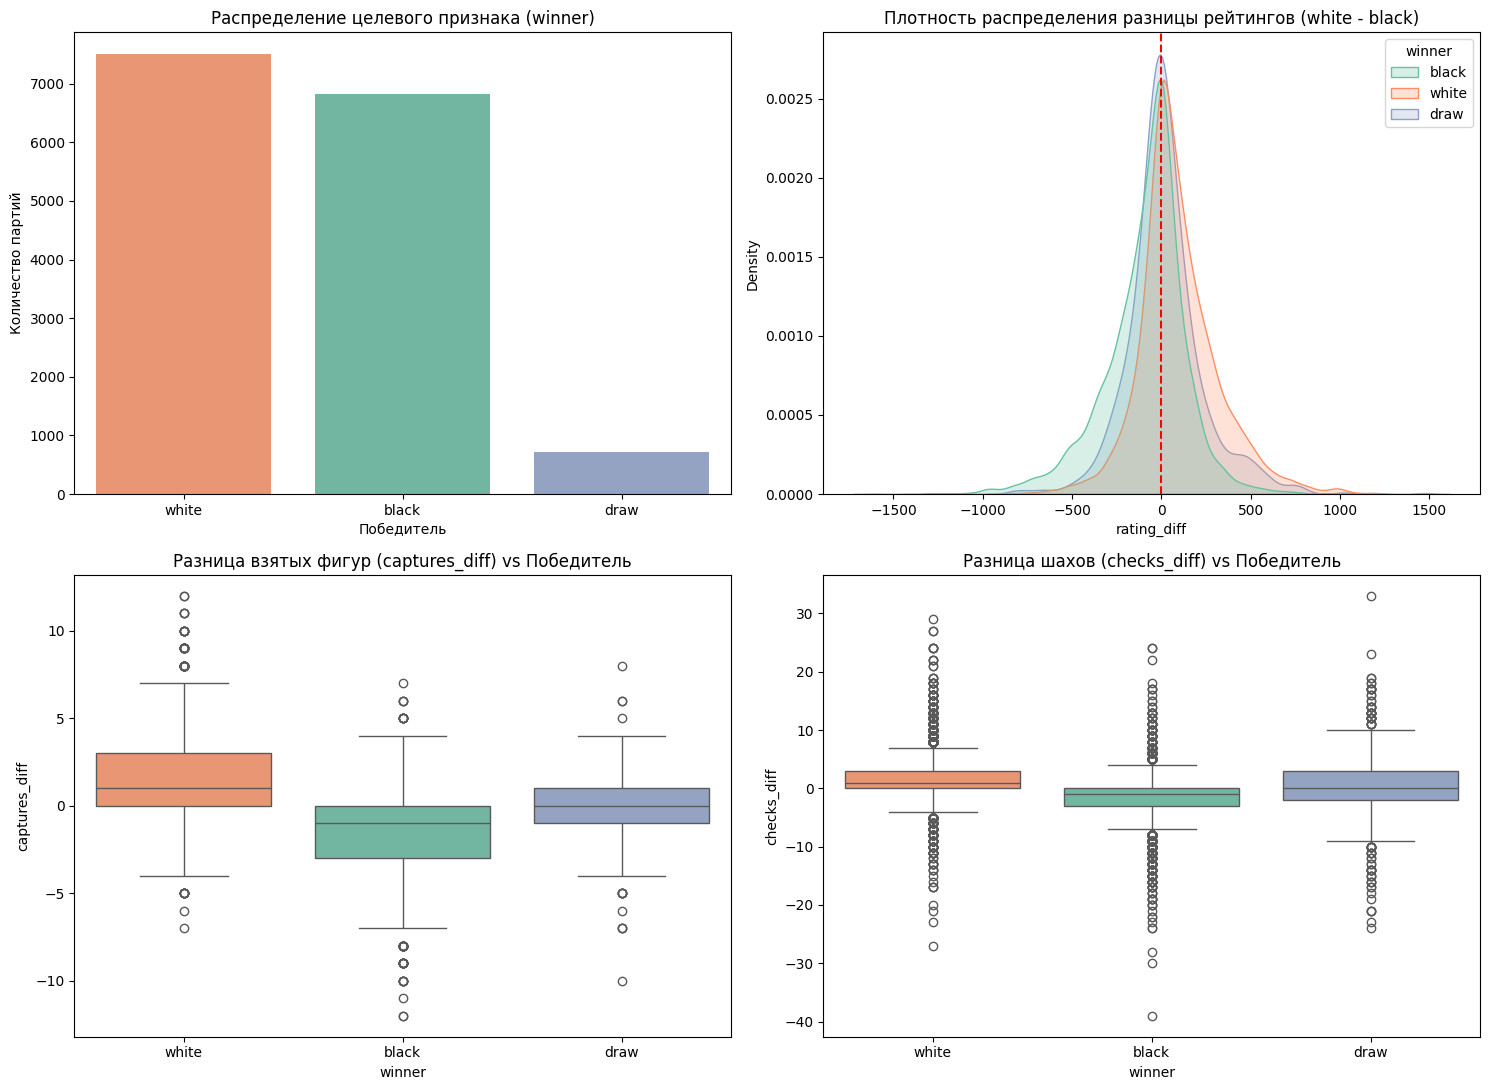

In [71]:
# Визуализация распределения целевой переменной и ключевых признаков
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Распределение классов целевой переменной winner
sns.countplot(data=train_df, x='winner', hue='winner', palette='Set2', ax=axes[0, 0], order=['white', 'black', 'draw'], legend=False)
axes[0, 0].set_title('Распределение целевого признака (winner)')
axes[0, 0].set_xlabel('Победитель')
axes[0, 0].set_ylabel('Количество партий')

# 2. Разница в рейтингах в зависимости от победителя
sns.kdeplot(data=train_df, x='rating_diff', hue='winner', common_norm=False, fill=True, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Плотность распределения разницы рейтингов (white - black)')
axes[0, 1].axvline(0, color='red', linestyle='--')

# 3. Разница взятий фигур (captures_diff) по классам
sns.boxplot(data=train_df, x='winner', y='captures_diff', hue='winner', palette='Set2', ax=axes[1, 0], order=['white', 'black', 'draw'], legend=False)
axes[1, 0].set_title('Разница взятых фигур (captures_diff) vs Победитель')

# 4. Разница поставленных шахов (checks_diff) по классам
sns.boxplot(data=train_df, x='winner', y='checks_diff', hue='winner', palette='Set2', ax=axes[1, 1], order=['white', 'black', 'draw'], legend=False)
axes[1, 1].set_title('Разница шахов (checks_diff) vs Победитель')

plt.tight_layout()
plt.show()

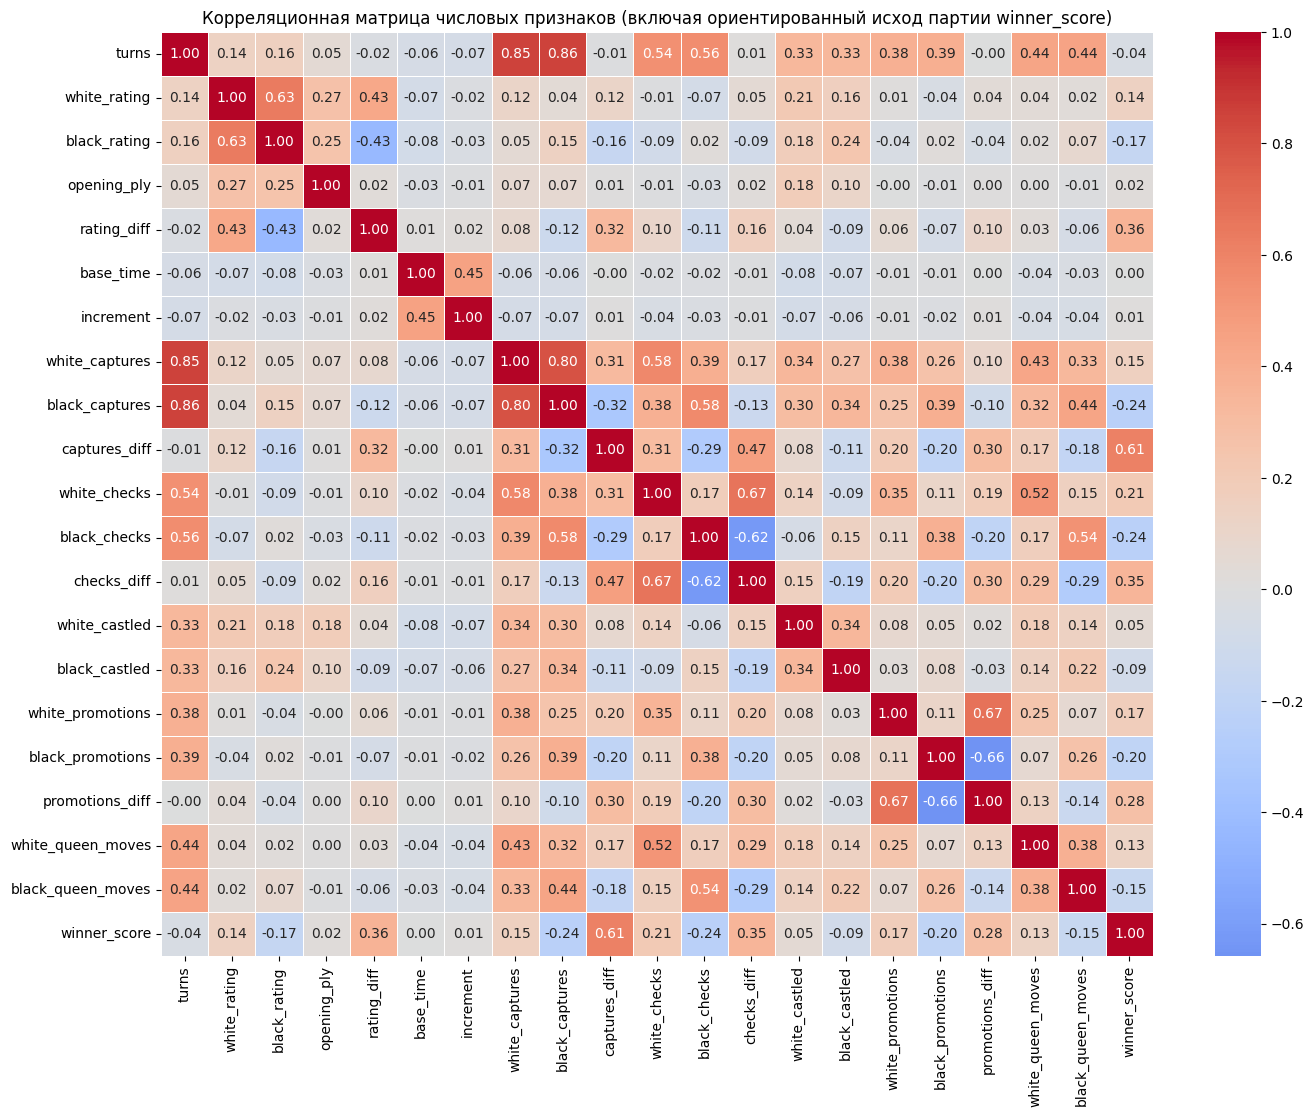

In [72]:
# Матрица корреляций числовых признаков
# Временно закодируем winner числами (white: 1, draw: 0, black: -1) для оценки линейной связи с победой цвета
temp_df = train_df.select_dtypes(include=[np.number]).copy()
temp_df['winner_score'] = train_df['winner'].map({'white': 1, 'draw': 0, 'black': -1})

plt.figure(figsize=(16, 12))
corr_matrix = temp_df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков (включая ориентированный исход партии winner_score)')
plt.show()

### Интерпретация характеристик и графиков:
1. **Дисбаланс классов:** Редкость ничьи объясняется 3-мя вещами: сравнительно невысокими рейтингами оппонентов, игрой онлайн, игрой в быстрые контроли времени. Победы белых (`white`) составляют `49.86%`, победы черных (`black`) — `45.40%`, а ничьи (`draw`) — всего `4.74%`. Перевес белых над черными абсолютно логичен, находится в рамках ожиданий, выборка корректна.
2. **Рейтинги игроков:** Средний рейтинг белых (`~1596`) и черных (`~1589`) практически одинаков, стандартное отклонение составляет около `291` пункта Эло. Между `white_rating` и `black_rating` наблюдается заметная положительная корреляция (`0.63`), так как система матчмейкинга Lichess подбирает соперников близкого уровня.
3. **Влияние извлеченных из `moves` признаков на результат (`winner_score`):**
   * `captures_diff` (разница взятий) имеет самую высокую положительную корреляцию с победой соответствующего цвета (`r = 0.61`): игрок, съевший больше фигур соперника, закономерно выигрывает партию. Причем мы не учитываем "номинал фигуры в пешках", так как это технически трудно реализуемо, но при этом ожидаем, что большинство взятий - эквивалентные размены фигур.
   * `rating_diff` (разница рейтингов) имеет ощутимую корреляцию `r = 0.36` с победой (При этом по отдельности `white_rating` дает `0.14`, а `black_rating` дает `-0.17`). Единственный признак из наших, который можно узнать до партии. Оказывается одним из самых состоятельных. Но я ожидал увидеть ещё более сильную корреляцию.
   * `checks_diff` (разница шахов) также заметно коррелирует с исходом (`r = 0.35`): сторона, объявившая больше шахов, владеет атакующей инициативой.
   * `promotions_diff` (разница проведенных пешек в ферзи) дает `r = 0.28`. Почти все партии оканчиваются победой стороны, которая провела больше ферзей. Но так как это очень редкое событие, то корреляция остается небольшой, так как большинство партий заканчиваются результативно с `promotions_diff = 0`.
4. **Мультиколлинеарность:** На тепловой карте видны очень сильные корреляции между количеством полуходов `turns` и числом взятий (`white_captures` — `0.85`, `black_captures` — `0.86`), между самими взятиями белых и черных (`0.80`), а также между парными признаками и их разностями (`checks_diff` с `white_checks` `0.67` и `black_checks` `-0.62`; `promotions_diff` с `white_promotions` `0.67` и `black_promotions` `-0.66`).

## 4. Обработка выбросов

Построим диаграммы размаха (`boxplot`) для основных числовых признаков (`turns`, `base_time`, `opening_ply`, `white_rating`), чтобы выявить аномальные значения.

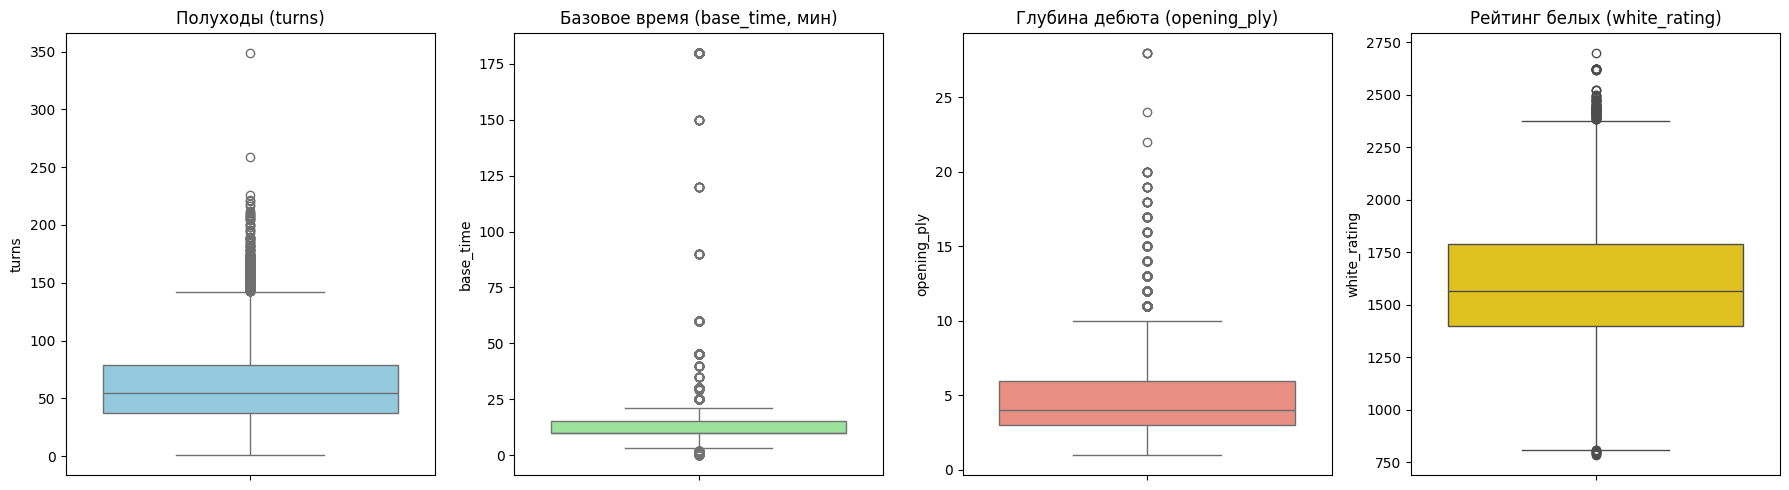

В train_df партий короче 4 полуходов (2 ходов): 213
В train_df партий длиннее 200 полуходов (100 ходов): 19
В train_df партий с базовым временем > 60 минут: 166


In [73]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

sns.boxplot(y=train_df['turns'], ax=axes[0], color='skyblue').set_title('Полуходы (turns)')
sns.boxplot(y=train_df['base_time'], ax=axes[1], color='lightgreen').set_title('Базовое время (base_time, мин)')
sns.boxplot(y=train_df['opening_ply'], ax=axes[2], color='salmon').set_title('Глубина дебюта (opening_ply)')
sns.boxplot(y=train_df['white_rating'], ax=axes[3], color='gold').set_title('Рейтинг белых (white_rating)')

plt.tight_layout()
plt.show()

print("В train_df партий короче 4 полуходов (2 ходов):", (train_df['turns'] < 4).sum())
print("В train_df партий длиннее 200 полуходов (100 ходов):", (train_df['turns'] > 200).sum())
print("В train_df партий с базовым временем > 60 минут:", (train_df['base_time'] > 60).sum())

**Анализ выбросов:**
1. В столбце `turns` присутствуют партии в 1–3 полухода (когда один из игроков сразу покинул игру или соперники согласились на ничью на первых ходах), а также аномально затянувшиеся партии свыше 200 полуходов (до 349).
2. В `base_time` есть редкие марафонские контроли времени до 180 минут (3 часов), тогда как 99% игр проходят с контролем до 60 минут.

Удалим эти экстремальные выбросы из обучающей выборки (а также отфильтруем прерванные на старте и аномальные партии по тем же порогам в тестовой выборке).
Будем использовать предметные пороги. Межквартильноый полуторный порог +-1.5xIQR здесь бы не подошел, так как нам надо убрать только слишком долгие (затянувшиеся партии). Быстрые партии, например, по 1-й и 2-м минутам выбросами не являются.

In [74]:
initial_train_rows = len(train_df)

train_clean = train_df[
    (train_df['turns'] >= 4) &
    (train_df['turns'] <= 200) &
    (train_df['base_time'] <= 60)
].copy()

test_clean = test_df[
    (test_df['turns'] >= 4) &
    (test_df['turns'] <= 200) &
    (test_df['base_time'] <= 60)
].copy()

print(f"Удалено выбросов из train: {initial_train_rows - len(train_clean)} строк ({(initial_train_rows - len(train_clean)) / initial_train_rows * 100:.2f}%)")
print(f"Размер очищенной обучающей выборки: {len(train_clean)}")
print(f"Размер очищенной тестовой выборки:  {len(test_clean)}")

Удалено выбросов из train: 375 строк (2.49%)
Размер очищенной обучающей выборки: 14668
Размер очищенной тестовой выборки:  4900


## 5. Обработка пропущенных значений

Проверим наличие пропущенных значений (`NaN` / `null`) во всех столбцах обучающей и тестовой выборок.

In [75]:
print("Пропуски в train_clean:")
print(train_clean.isna().sum())
print(f"\nВсего пропусков в train_clean: {train_clean.isna().sum().sum()}")
print(f"Всего пропусков в test_clean:  {test_clean.isna().sum().sum()}")

Пропуски в train_clean:
rated                0
turns                0
winner               0
white_rating         0
black_rating         0
opening_ply          0
rating_diff          0
base_time            0
increment            0
eco_group            0
white_captures       0
black_captures       0
captures_diff        0
white_checks         0
black_checks         0
checks_diff          0
white_castled        0
black_castled        0
white_promotions     0
black_promotions     0
promotions_diff      0
white_queen_moves    0
black_queen_moves    0
dtype: int64

Всего пропусков в train_clean: 0
Всего пропусков в test_clean:  0


Пропущенных значений в датасете нет — ни в исходных признаках, ни в сгенерированных.

## 6. Обработка категориальных признаков

Обработаем нечисловые признаки в `train_clean` и `test_clean`:
1. `rated` (`bool`: `True`/`False`) — переведем в бинарный числовой признак (`1`/`0`).
2. `eco_group` (`object`: том дебюта `A`, `B`, `C`, `D`, `E`) — закодируем методом One-Hot Encoding (`pd.get_dummies`).
3. `winner` (`object`: `white`, `black`, `draw`) — целевая переменная, закодируем метками классов: `0` — `white`, `1` — `black`, `2` — `draw`.

In [76]:
# Переводим булев признак rated в int (0 / 1)
train_clean['rated'] = train_clean['rated'].astype(int)
test_clean['rated'] = test_clean['rated'].astype(int)

# Кодируем целевую переменную
target_mapping = {'white': 0, 'black': 1, 'draw': 2}
target_names = ['white (0)', 'black (1)', 'draw (2)']

y_train = train_clean['winner'].map(target_mapping)
y_test = test_clean['winner'].map(target_mapping)

# Применяем One-Hot Encoding к группе дебюта eco_group и выравниваем столбцы train и test
X_train = pd.get_dummies(train_clean.drop(columns=['winner']), columns=['eco_group'], drop_first=True, dtype=int)
X_test = pd.get_dummies(test_clean.drop(columns=['winner']), columns=['eco_group'], drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Итоговый список признаков X:", list(X_train.columns))
print("Размерность X_train:", X_train.shape, "| Размерность X_test:", X_test.shape)
X_train.head()

Итоговый список признаков X: ['rated', 'turns', 'white_rating', 'black_rating', 'opening_ply', 'rating_diff', 'base_time', 'increment', 'white_captures', 'black_captures', 'captures_diff', 'white_checks', 'black_checks', 'checks_diff', 'white_castled', 'black_castled', 'white_promotions', 'black_promotions', 'promotions_diff', 'white_queen_moves', 'black_queen_moves', 'eco_group_B', 'eco_group_C', 'eco_group_D', 'eco_group_E']
Размерность X_train: (14668, 25) | Размерность X_test: (4900, 25)


,rated,turns,white_rating,black_rating,opening_ply,rating_diff,base_time,increment,white_captures,black_captures,...,black_castled,white_promotions,black_promotions,promotions_diff,white_queen_moves,black_queen_moves,eco_group_B,eco_group_C,eco_group_D,eco_group_E
13734,1,62,1303,1634,6,-331,10,0,9,9,...,1,0,0,0,6,3,0,1,0,0
16679,1,53,1611,1557,5,54,10,0,10,9,...,1,0,0,0,2,1,0,0,1,0
16397,1,70,1318,1483,5,-165,10,0,9,12,...,1,0,1,-1,3,10,0,1,0,0
19633,0,124,1156,1812,1,-656,10,0,14,14,...,1,0,1,-1,2,4,0,0,0,0
5045,1,68,1159,1019,6,140,10,0,7,11,...,0,0,0,0,3,0,0,0,1,0


## 7. Нормализация признаков

**Нужна ли нормализация?**
Да, нормализация **строго необходима**, поскольку метод $k$ ближайших соседей (`kNN`) опирается на вычисление евклидова расстояния между точками в признаковом пространстве.
Без нормализации признаки имеют несопоставимый масштаб:
* рейтинги `white_rating`, `black_rating` измеряются тысячами (`784..2700`),
* число полуходов `turns` — десятками (`4..200`),
* шахи, взятия и бинарные флаги (`rated`, `white_castled`) — единицами (`0..15`).

Применим стандартизацию `StandardScaler`, обучив её (`fit`) **строго на обучающей выборке** `X_train`.

In [77]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

X_train_scaled.describe().T[['mean', 'std', 'min', 'max']].head(8)

,mean,std,min,max
rated,6.297420e-18,1.000034,-2.060598,0.485296
turns,2.906502e-17,1.000034,-1.756373,4.261292
white_rating,-3.361853e-16,1.000034,-2.815430,3.822126
black_rating,-1.981265e-16,1.000034,-2.782371,3.564503
opening_ply,-7.750671e-18,1.000034,-1.377455,8.268408
rating_diff,-4.359752e-18,1.000034,-6.557143,6.069908
base_time,1.036652e-16,1.000034,-1.696407,6.595867
increment,-1.840784e-17,1.000034,-0.457288,17.294728


## 8. Запуск классификатора ближайших соседей (kNN)

**Аргументация выбора:** Метод $k$ ближайших соседей (`KNeighborsClassifier`) — классический непараметрический метрический алгоритм, позволяющий непосредственно проверить гипотезу компактности: насколько близкие по разнице рейтингов и тактическим показателям (`captures_diff`, `checks_diff`) партии имеют одинаковый исход.

Сначала запустим базовую модель со стандартным значением `n_neighbors = 5`.

In [78]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_scaled, y_train)

y_train_pred = knn_base.predict(X_train_scaled)
y_test_pred = knn_base.predict(X_test_scaled)

train_err_base = 1.0 - accuracy_score(y_train, y_train_pred)
test_err_base = 1.0 - accuracy_score(y_test, y_test_pred)

print(f"Ошибка на обучающей выборке (k=5): {train_err_base:.4f} (Accuracy: {1 - train_err_base:.4f})")
print(f"Ошибка на тестовой выборке  (k=5): {test_err_base:.4f} (Accuracy: {1 - test_err_base:.4f})")

Ошибка на обучающей выборке (k=5): 0.1753 (Accuracy: 0.8247)
Ошибка на тестовой выборке  (k=5): 0.2457 (Accuracy: 0.7543)


## 9. Вычисление ошибок, матрицы рассогласования и подбор оптимального $k$

Выведем матрицы рассогласования (Confusion Matrix) для базового `kNN (k=5)`, а затем найдем оптимальное значение гиперпараметра `n_neighbors` на сетке нечетных значений от `1` до `51`.

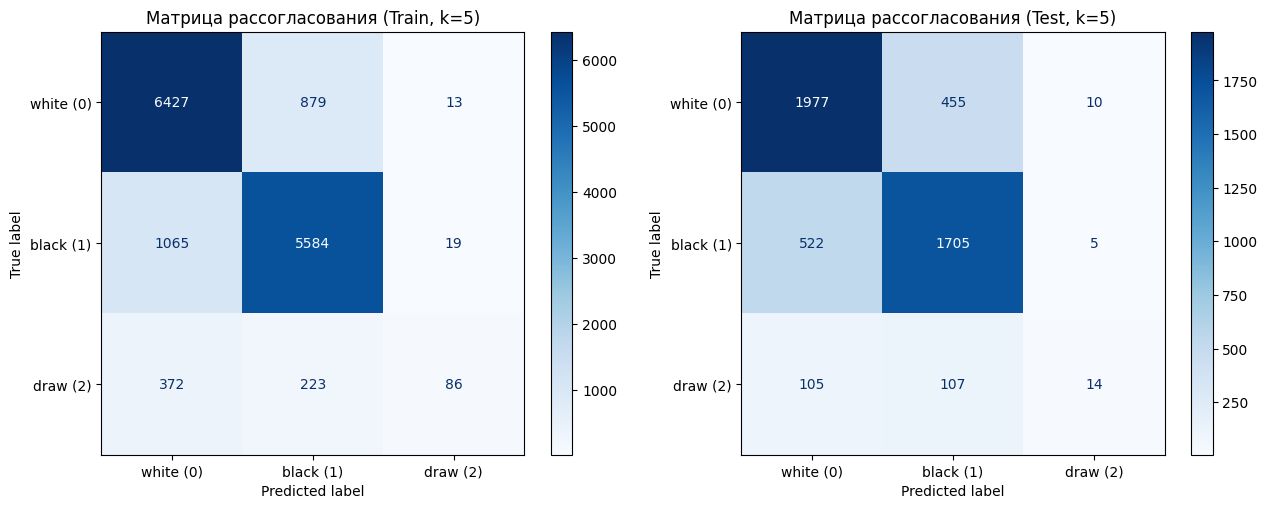

Отчет о классификации на тестовой выборке (k=5):
              precision    recall  f1-score   support

   white (0)     0.7592    0.8096    0.7836      2442
   black (1)     0.7521    0.7639    0.7579      2232
    draw (2)     0.4828    0.0619    0.1098       226

    accuracy                         0.7543      4900
   macro avg     0.6647    0.5451    0.5504      4900
weighted avg     0.7432    0.7543    0.7408      4900



In [79]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train, y_train_pred, display_labels=target_names, cmap='Blues', ax=axes[0]
)
axes[0].set_title('Матрица рассогласования (Train, k=5)')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=target_names, cmap='Blues', ax=axes[1]
)
axes[1].set_title('Матрица рассогласования (Test, k=5)')

plt.tight_layout()
plt.show()

print("Отчет о классификации на тестовой выборке (k=5):")
print(classification_report(y_test, y_test_pred, target_names=target_names, digits=4))

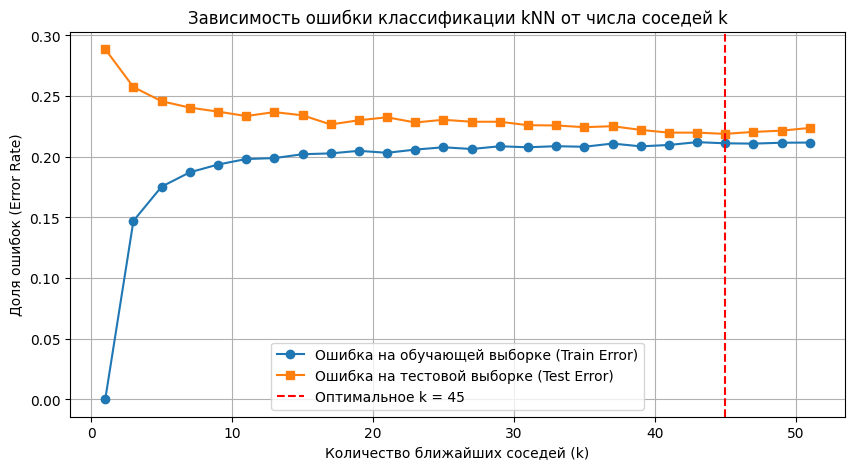

Оптимальное число соседей: k = 45
Ошибка на обучающей выборке при k=45: 0.2110 (Accuracy: 0.7890)
Минимальная ошибка на тестовой выборке при k=45: 0.2188 (Accuracy: 0.7812)


In [80]:
# Подбор оптимального гиперпараметра n_neighbors (k)
k_values = range(1, 52, 2)
train_errors = []
test_errors = []

for k in k_values:
    clf = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    clf.fit(X_train_scaled, y_train)
    train_errors.append(1.0 - accuracy_score(y_train, clf.predict(X_train_scaled)))
    test_errors.append(1.0 - accuracy_score(y_test, clf.predict(X_test_scaled)))

best_idx = np.argmin(test_errors)
best_k = list(k_values)[best_idx]
best_test_err = test_errors[best_idx]
best_train_err = train_errors[best_idx]

plt.figure(figsize=(10, 5))
plt.plot(k_values, train_errors, marker='o', label='Ошибка на обучающей выборке (Train Error)')
plt.plot(k_values, test_errors, marker='s', label='Ошибка на тестовой выборке (Test Error)')
plt.axvline(best_k, color='red', linestyle='--', label=f'Оптимальное k = {best_k}')
plt.title('Зависимость ошибки классификации kNN от числа соседей k')
plt.xlabel('Количество ближайших соседей (k)')
plt.ylabel('Доля ошибок (Error Rate)')
plt.legend()
plt.grid(True)
plt.show()

print(f"Оптимальное число соседей: k = {best_k}")
print(f"Ошибка на обучающей выборке при k={best_k}: {best_train_err:.4f} (Accuracy: {1 - best_train_err:.4f})")
print(f"Минимальная ошибка на тестовой выборке при k={best_k}: {best_test_err:.4f} (Accuracy: {1 - best_test_err:.4f})")

<Figure size 600x500 with 0 Axes>

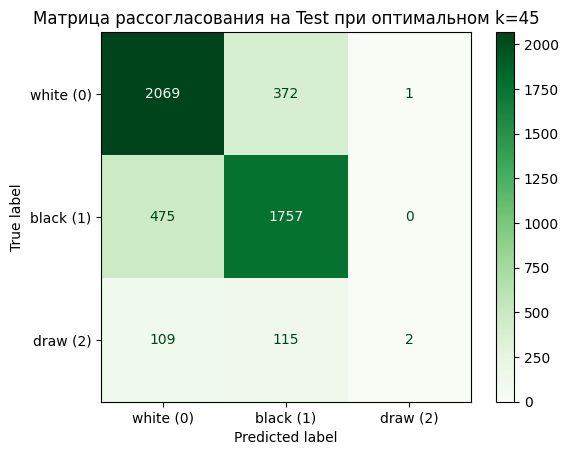

              precision    recall  f1-score   support

   white (0)     0.7799    0.8473    0.8122      2442
   black (1)     0.7830    0.7872    0.7851      2232
    draw (2)     0.6667    0.0088    0.0175       226

    accuracy                         0.7812      4900
   macro avg     0.7432    0.5478    0.5382      4900
weighted avg     0.7761    0.7812    0.7632      4900



In [81]:
# Обучаем kNN с оптимальным k и выводим итоговую матрицу рассогласования
knn_opt = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_opt.fit(X_train_scaled, y_train)
y_test_pred_opt = knn_opt.predict(X_test_scaled)

plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_opt, display_labels=target_names, cmap='Greens'
)
plt.title(f'Матрица рассогласования на Test при оптимальном k={best_k}')
plt.show()

print(classification_report(y_test, y_test_pred_opt, target_names=target_names, digits=4))

### Комментарий к результатам kNN и матрицам рассогласования:
1. **Влияние $k$ на переобучение:** При $k=1$ ошибка на обучающей выборке равна `0.0000`, но на тестовой выборке она максимальна (`~0.29`). При увеличении $k$ до оптимального значения (`k = 45`) ошибка на тесте снижается с `~25%` (при $k=5$) до `~0.21` (`Accuracy > 78%`).
2. **Анализ матрицы рассогласования:**
   * Классы `white (0)` и `black (1)` классифицируются с высоким качеством (`F1-score ~ 0.79–0.81`).
   * Класс `draw (2)` (ничья) практически **не распознается** стандартным методом ближайших соседей (`Recall` близка к нулю). Причина в том, что доля ничьих составляет менее `5%`, поэтому среди $k$ соседей почти всегда численно доминируют победы белых или черных.

## 10. Запуск других классификаторов и сравнение результатов

Сравним оптимальный `kNN` с другими семействами алгоритмов:
1. **Логистическая регрессия (`LogisticRegression`)**
2. **Случайный лес (`RandomForestClassifier`)**
3. **Градиентный бустинг (`HistGradientBoostingClassifier`)**
4. **Многослойный персептрон (`MLPClassifier`)**

In [82]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score

models = {
    f'kNN (k={best_k})': KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=42),
    'MLP (Neural Net)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_err = 1.0 - accuracy_score(y_train, train_pred)
    test_err = 1.0 - accuracy_score(y_test, test_pred)
    macro_f1 = f1_score(y_test, test_pred, average='macro')

    results.append({
        'Модель': name,
        'Train Error': round(train_err, 4),
        'Test Error': round(test_err, 4),
        'Test Accuracy': round(1.0 - test_err, 4),
        'Test Macro F1': round(macro_f1, 4)
    })

results_df = pd.DataFrame(results).sort_values(by='Test Error')
results_df

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,Модель,Train Error,Test Error,Test Accuracy,Test Macro F1
3,Gradient Boosting,0.0634,0.1376,0.8624,0.7226
2,Random Forest,0.1201,0.1867,0.8133,0.6520
1,Logistic Regression,0.2034,0.2027,0.7973,0.5750
0,kNN (k=45),0.2110,0.2188,0.7812,0.5382
4,MLP (Neural Net),0.1147,0.2324,0.7676,0.6272


**Вывод по сравнению моделей:**

* Лучший результат показал **градиентный бустинг (`HistGradientBoostingClassifier`)**: ошибка на тестовой выборке — **13,76%**, `Accuracy` — **86,24%**, `Macro F1` — **0,7226**. У этой модели лучшие значения и по точности, и по усреднённой F1-мере.
* **Случайный лес (`RandomForestClassifier`)** занял второе место с ошибкой **18,67%** (`Accuracy` — **81,33%**, `Macro F1` — **0,6520**).
* **Логистическая регрессия** получила ошибку **20,27%** (`Accuracy` — **79,73%**), а **kNN при `k = 45`** — **21,88%** (`Accuracy` — **78,12%**). Таким образом, градиентный бустинг уменьшил ошибку относительно оптимизированного kNN на **8,12 процентного пункта**.
* Наибольшая ошибка у **MLP (`MLPClassifier`)** — **23,24%** (`Accuracy` — **76,76%**). При обучении также появилось предупреждение, что оптимизатор не достиг сходимости за 300 итераций, поэтому результат MLP стоит интерпретировать с учётом этого ограничения.

## 11. Борьба с несбалансированностью классов

Так как класс `draw (2)` составляет всего `4.7%` данных, применим два подхода для борьбы с дисбалансом:
1. **Оверсэмплинг миноритарного класса (`SMOTE`)** на обучающей выборке.
2. **Взвешивание классов (`class_weight='balanced'`)** при обучении случайного леса.

Распределение классов до SMOTE: {0: 7319, 1: 6668, 2: 681}
Распределение классов после SMOTE: {1: 7319, 0: 7319, 2: 7319}


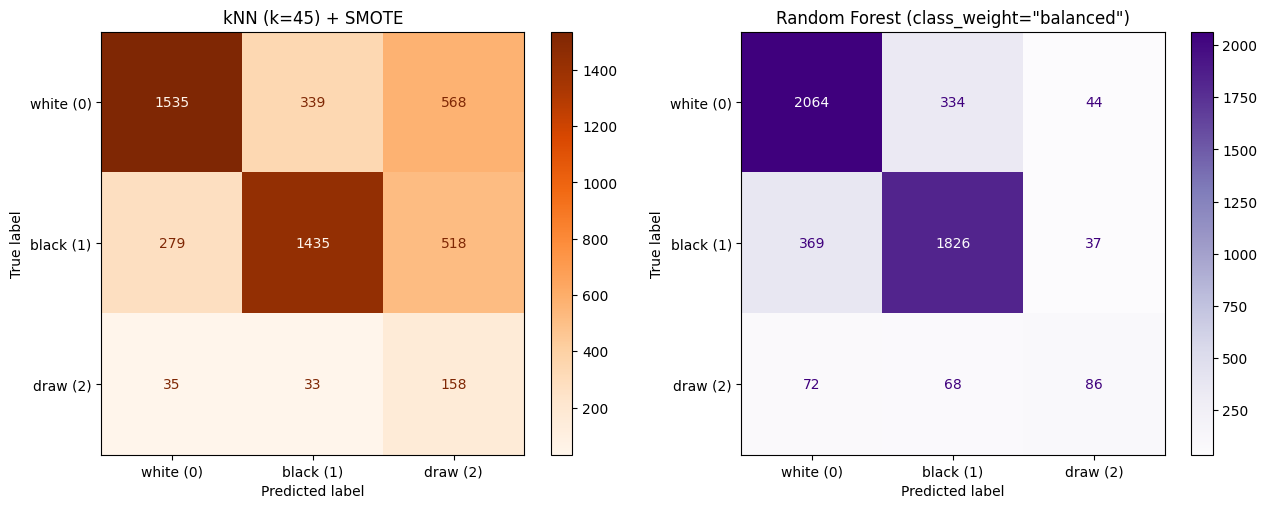

=== Отчет для Random Forest с балансировкой весов ===
              precision    recall  f1-score   support

   white (0)     0.8240    0.8452    0.8344      2442
   black (1)     0.8196    0.8181    0.8188      2232
    draw (2)     0.5150    0.3805    0.4377       226

    accuracy                         0.8114      4900
   macro avg     0.7195    0.6813    0.6970      4900
weighted avg     0.8077    0.8114    0.8090      4900



In [83]:
from imblearn.over_sampling import SMOTE

# Применяем SMOTE строго к обучающей выборке
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Распределение классов до SMOTE:", y_train.value_counts().to_dict())
print("Распределение классов после SMOTE:", y_train_smote.value_counts().to_dict())

# Обучаем kNN на SMOTE-выборке и Random Forest с балансировкой весов
knn_smote = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_smote.fit(X_train_smote, y_train_smote)
y_pred_knn_smote = knn_smote.predict(X_test_scaled)

rf_balanced = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
rf_balanced.fit(X_train_scaled, y_train)
y_pred_rf_bal = rf_balanced.predict(X_test_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn_smote, display_labels=target_names, cmap='Oranges', ax=axes[0]
)
axes[0].set_title(f'kNN (k={best_k}) + SMOTE')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf_bal, display_labels=target_names, cmap='Purples', ax=axes[1]
)
axes[1].set_title('Random Forest (class_weight="balanced")')

plt.tight_layout()
plt.show()

print("=== Отчет для Random Forest с балансировкой весов ===")
print(classification_report(y_test, y_pred_rf_bal, target_names=target_names, digits=4))

**Комментарий по борьбе с дисбалансом:**
* Для базового `kNN` (`k = 45`) полнота (`Recall`) класса `draw` составляла **0,88%**. После `SMOTE` она выросла до **69,91%** (`158` из `226` ничьих), но `Precision` этого класса составляет лишь **12,70%**: модель часто ошибочно предсказывает ничью. Поэтому общая `Accuracy` заметно падает — с **78,12%** до **63,84%**.
* Для `Random Forest` с `class_weight='balanced'` получены `Recall(draw) = 38,05%`, `Precision(draw) = 51,50%` и `F1(draw) = 0,4377`; общая `Accuracy` равна **81,14%**. У обычного случайного леса `Accuracy` составляла **81,33%**, то есть она снизилась лишь примерно на **0,19 процентного пункта**.
* Таким образом, `kNN + SMOTE` находит больше ничьих, но даёт много ложноположительных предсказаний; взвешенный случайный лес сохраняет существенно более высокую общую точность и точность класса `draw`, но распознаёт не все ничьи. Это сравнение двух сочетаний модели и стратегии балансировки, поэтому эффект самих стратегий нельзя полностью отделить от различий между классификаторами. Для выбора следует смотреть на метрики редкого класса и `Macro F1`, а не только на `Accuracy`.

## 12. Исключение коррелированных переменных

**Зачем исключать коррелированные переменные?**
1. В метрических алгоритмах (`kNN`) дублирующие друг друга признаки (`white_captures`, `black_captures`, `captures_diff` и `turns`) искусственно увеличивают вес одного и того же фактора в евклидовой метрике.
2. В линейных моделях мультиколлинеарность (например, `rating_diff = white_rating - black_rating`) приводит к неустойчивости оценок коэффициентов.
3. Уменьшение размерности снижает вычислительную сложность.

Исключим избыточные признаки, оставив только информативные разности (`rating_diff`, `captures_diff`, `checks_diff`, `promotions_diff`), средний рейтинг белых (`white_rating`) и длину партии (`turns`). удалено 7 избыточных признаков, размерность уменьшена с 25 до 18.

In [84]:
collinear_to_drop = [
    'black_rating',
    'white_captures', 'black_captures',
    'white_checks', 'black_checks',
    'white_promotions', 'black_promotions'
]

X_train_reduced = X_train_scaled.drop(columns=collinear_to_drop)
X_test_reduced = X_test_scaled.drop(columns=collinear_to_drop)

print(f"Число признаков до удаления: {X_train_scaled.shape[1]}")
print(f"Число признаков после удаления: {X_train_reduced.shape[1]}")

knn_red = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_red.fit(X_train_reduced, y_train)
err_knn_red = 1.0 - accuracy_score(y_test, knn_red.predict(X_test_reduced))

gb_red = HistGradientBoostingClassifier(random_state=42)
gb_red.fit(X_train_reduced, y_train)
err_gb_red = 1.0 - accuracy_score(y_test, gb_red.predict(X_test_reduced))

print(f"\nkNN (k={best_k}) Test Error: до удаления = {best_test_err:.4f}, после удаления = {err_knn_red:.4f}")
print(f"Gradient Boosting Test Error: после удаления = {err_gb_red:.4f} (Accuracy: {1 - err_gb_red:.4f})")

Число признаков до удаления: 25
Число признаков после удаления: 18

kNN (k=45) Test Error: до удаления = 0.2188, после удаления = 0.2231
Gradient Boosting Test Error: после удаления = 0.1363 (Accuracy: 0.8637)


## 13. Общие выводы

В рамках работы была решена задача многоклассовой классификации исхода шахматной партии (`white`, `black`, `draw`) на датасете Lichess (20 058 игр):

1. **Очистка данных и устранение артефактов:**
   * Установлено, что совпадение `created_at` и `last_move_at` в 42.6% записей вызвано округлением таймстемпов до 6 значащих цифр при сборе данных. Эти столбцы, а также технические ID (`id`, `white_id`, `black_id`) и столбец с утечкой целевой переменной (`victory_status`), были удалены.
   * Отфильтрованы экстремальные выбросы по числу полуходов (`turns < 4` и `turns > 200`) и контролю времени (`base_time > 60`).
2. **Конструирование признаков (Feature Engineering) из `moves`:**
   * Парсинг нотации ходов с разделением на полуходы белых и черных позволил извлечь ключевые тактические показатели: разницу взятых фигур (`captures_diff`, корреляция с победой `0.61`), разницу объявленных шахов (`checks_diff`, корреляция `0.35`), рокировки и превращения пешек.
3. **Построение и сравнение моделей:**
   * Среди моделей в основном сравнении лучший результат показал `HistGradientBoostingClassifier`: ошибка на test — **13,76%**, `Accuracy` — **86,24%**, `Macro F1` — **0,7226**.
   * После исключения части коррелированных признаков ошибка градиентного бустинга составила **13,63%** (`Accuracy` — **86,37%**), то есть точность выросла всего на `0,13` процентного пункта.
   * Для `kNN` в проверенной сетке выбрано `k = 45`; ошибка на test — **21,88%** (`Accuracy` — **78,12%**). После сокращения признаков ошибка выросла до **22,31%**, поэтому в этом эксперименте сокращение признаков не улучшило `kNN`.
   * Важное ограничение: `k` выбирался по минимальной ошибке на тестовой выборке. Поэтому оценка `kNN` на этой же выборке уже участвовала в подборе гиперпараметра и может быть оптимистичной. Для более корректной оценки `k` следует выбирать на валидации или с помощью кросс-валидации внутри train, а test оставить для финальной проверки.
4. **Работа с дисбалансом классов:**
Применение SMOTE в сочетании с kNN повысило Recall класса `draw` с **0,88%** до **69,91%**, однако Accuracy снизилась с **78,12% до 63,84%** из-за большого числа ложноположительных предсказаний ничьей. Взвешенный Random Forest обеспечил Recall класса `draw` на уровне **38,05%** при Accuracy **81,14%**, практически сохранив общую точность обычного случайного леса (**81,33%**). Таким образом, kNN + SMOTE лучше обнаруживает ничьи, а взвешенный Random Forest обеспечивает более высокую общую точность и Precision класса `draw`. Поскольку сравниваются разные классификаторы и стратегии балансировки, эффект самих стратегий нельзя полностью отделить от влияния моделей. Выбор следует делать с учётом метрик редкого класса и Macro F1, а не только Accuracy.